# Setup

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

# import custom helper functions
# !cp "/content/gdrive/MyDrive/Colab Notebooks/latent/src/model_utils.py" .
# !cp "/content/gdrive/MyDrive/Colab Notebooks/latent/src/feature_utils.py" .
!cp "/content/gdrive/MyDrive/Colab Notebooks/latent/src/evaluation_utils.py" .

!rm -rf DL4CM # clear up dir if any
!git clone https://github.com/ti55987/DL4CM.git

Mounted at /content/gdrive
Cloning into 'DL4CM'...
remote: Enumerating objects: 254, done.
remote: Counting objects: 100% (254/254), done.
remote: Compressing objects: 100% (178/178), done.
remote: Total 254 (delta 145), reused 177 (delta 68), pack-reused 0 (from 0)
Receiving objects: 100% (254/254), 6.50 MiB | 8.28 MiB/s, done.
Resolving deltas: 100% (145/145), done.


In [2]:
%cd DL4CM
%ls

/content/DL4CM
ann_loss_exp.ipynb     mixture_models.py          simulation/
data_inspection.ipynb  mle.ipynb                  smc_pf.ipynb
environment_kera3.yml  models.py                  tools/
environment.yml        permutation_test.ipynb     utils/
likelihood.py          rl_models.py
matrix.py              rnn_encoder_decoder.ipynb


In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

import logging
import time
import math
import os
import plotnine as gg

from scipy import stats
import seaborn as sns
from functools import partial
from datetime import datetime

from utils.feature_utils import (
    get_labels,
    get_condition_aware_labels,
    get_block_features,
    get_iter_acc_without_switches,
    get_iter_acc_with_switches,
    extract_features_blockless,
)

from utils.model_utils import set_seed

from sklearn.model_selection import train_test_split

# Read Data

In [4]:
# @title Helpers
from typing import List, Optional, Tuple

def plot_loss(history, loss_file, save_fig=False):
  x_length = len(history['loss'])
  plt.plot(history['loss'], label = 'training')
  plt.plot(history['val_loss'], label = 'validation')
  plt.xlabel('epoch')
  plt.ylabel('loss')
  leg = plt.legend(loc='upper right')
  if save_fig:
    plt.savefig(loss_file)

  plt.show()

def concat_by_cols(a, b):
  return np.hstack([a, b]) if a.size else b

def padding(data,  max_num_trial: int, num_trials: int):
  paddings = tf.constant([[0, max_num_trial-num_trials], [0, 0]])
  a_list = tf.unstack(data)
  for j in range(len(data)):
    padded_inputs = tf.pad(data[j], paddings, "CONSTANT", constant_values=-1)
    a_list[j] = padded_inputs

  return tf.stack(a_list)

def get_features_by_trials(data, n_agent, n_trial, n_action=2, mode=''):
    from tensorflow import one_hot
    from tensorflow.python.keras.layers import Concatenate

    # Probablistic RL
    action = data['actions'].to_numpy().astype(np.int32).reshape((n_agent, n_trial))
    reward = data['rewards'].to_numpy().astype(np.float32).reshape((n_agent, n_trial))

    # turn action into one-hot
    action_onehot = one_hot(action, n_action)
    # concatenate reward with action
    return Concatenate(axis=2)([reward[:, :, np.newaxis], action_onehot])

def load_multiple_files(model):
  list_of_train_files = {
       'RLF': ['RLF-6S3A/rand500_st11_18000a_12b_78t_rlf', 'RLF-6S3A/rand_500seqs_9000a_12b_78t_rlf'],
       'WM': ["WM-6S3A/rand500_st11_18000a_12b_78t_wm", "WM-6S3A/rand500_st11_9000a_12b_78t_wm"]}

  training_data = None
  for f in list_of_train_files[model]:
    data = pd.read_csv(f'{DATA_DIR}/{f}.csv')
    n_agent = len(data['agentid'].unique())
    if training_data is not None:
      data['agentid'] = data['agentid'] + training_data.agentid.max() + 1
      training_data = pd.concat([training_data, data])
    else:
      training_data = data

    del data # save memory

  print(len(training_data.agentid.unique()))
  return training_data

def load_all_model_data(model_list: list, mode_to_dir: dict, load_test: bool, concat: bool):
  model_to_features = []
  for idx in range(len(model_list)):
    m = model_list[idx]
    print(f'Loading data for {m}...')
    if m in ['RLF', 'WM'] and not load_test and concat:
      data = load_multiple_files(m)
    else:
      filename = mode_to_dir[m]['filename']
      filename = mode_to_dir[m]['test_file'] if load_test else mode_to_dir[m]['filename']
      data = pd.read_csv(f"{DATA_DIR}/{filename}")

    data['model_type'] = m
    model_to_features.append(data)
    # optimize later...
    #del data

  return pd.concat(model_to_features)

def process_data(model_idx_to_features: list, num_agents: int, max_num_trial: int, list_trials: list):
  features = []
  labels = np.array([])
  for num_trials in list_trials:
    for idx in range(len(model_idx_to_features)):
      all_trials_features = model_idx_to_features[idx]
      if num_trials == max_num_trial:
        padded_inputs = all_trials_features[:num_agents]
      else:
        padded_inputs = padding(all_trials_features[:num_agents, :num_trials], max_num_trial, num_trials)
      features.append(padded_inputs)
      labels = concat_by_cols(labels, np.repeat(idx, num_agents))

  return tf.concat(features, 0), tf.keras.utils.to_categorical(labels, num_classes=OUPUT_DIM)

def prepare_model_dataset(
    data: pd.DataFrame,
    feature_list: Optional[List[str]] = None,
    sorted_col: Optional[List[str]] = None,
    one_hot_encoding: Optional[List[str]] = None,
    sorting: bool = True,
    test_size: float = 0.1,
    random_state: int = 42,
    verbose: bool = True,
) -> Tuple[
    tf.Tensor,
    tf.Tensor,
    tf.Tensor,
    tf.Tensor,
    np.ndarray,
]:
    """Extracts features per model type, performs train/validation split, and

    returns concatenated TensorFlow tensors alongside one-hot encoded labels.
    """
    if feature_list is None:
        feature_list = [
            "actions",
            "rewards",
            "stim_iter",
            "isswitch",
            "prev_action",
            "delay_since_last_stimuli",
        ]
    if sorted_col is None:
        sorted_col = ["agentid", "block_no", "stimuli"]
    if one_hot_encoding is None:
        one_hot_encoding = []

    model_types = data["model_type"].unique()
    num_classes = len(model_types)

    train_features, val_features = [], []
    train_labels, val_labels = [], []

    for idx, (model_name, group_data) in enumerate(
        data.groupby("model_type", sort=False)
    ):
        td_iter = group_data.copy()

        # Vectorized switch calculation (faster than .apply)
        td_iter["isswitch"] = (td_iter["trials"] == 0).astype(int)

        # Retain DataFrame index alignment to avoid index mismatch
        td_iter["prev_action"] = (
            group_data.groupby(["agentid", "block_no"])["actions"]
            .shift(1)
            .fillna(-1)
            .astype(int)
        )

        td_iter_order = (
            td_iter.sort_values(by=sorted_col) if sorting else td_iter
        )

        features = extract_features_blockless(
            td_iter_order, feature_list, one_hot_encoding
        )
        labels = [idx] * len(features)

        trf, valf, train_l, val_l = train_test_split(
            features, labels, test_size=test_size, random_state=random_state
        )

        train_features.append(trf)
        val_features.append(valf)
        train_labels.extend(train_l)
        val_labels.extend(val_l)

        if verbose:
            print(f"Model: {model_name:<15} | Features shape: {features.shape}")

    # Convert to Tensors
    X_train = tf.concat(train_features, axis=0)
    X_val = tf.concat(val_features, axis=0)
    y_train = tf.keras.utils.to_categorical(train_labels, num_classes=num_classes)
    y_val = tf.keras.utils.to_categorical(val_labels, num_classes=num_classes)

    if verbose:
        print(f"\nFinal Train Shape: {X_train.shape} | Val Shape: {X_val.shape}")

    return X_train, X_val, y_train, y_val, model_types

In [6]:
# Constants
DRIVE_DIR = '/content/gdrive/Shareddrives/DLCCM/blocks'
task = 'model_identification'
RESULT_DIR = f'{DRIVE_DIR}/results/{task}'
DATA_DIR = f'/content/gdrive/MyDrive/Colab Notebooks/data'
N_TRAIN_AGENT, N_TEST_AGENT = 9000, 100
num_blocks = 12

TEST_RESULT_DIR = RESULT_DIR + '/RLF-WM'
LIST_OF_MODELS = ['RLF', 'WM']
OUPUT_DIM = len(LIST_OF_MODELS)

mode_to_dir = {
    '2PRL': {
        'filename': f'seq1_{N_TRAIN_AGENT}a_12b_78t_2param_rl_no_switch.csv',
        'test_file': 'seq1_100a_12b_78t_2param_rl_no_switch.csv',
    },
    '3PRL': {
        'filename': f'3PRL-SA6/seq1_{N_TRAIN_AGENT}a_12b_78t_3param_rl_beta.csv',
        'test_file': '3PRL-SA6/seq1_100a_12b_78t_3param_rl_beta.csv',
    },
    '4PRL': {
        'filename': f'seq1_{N_TRAIN_AGENT}a_12b_78t_4param_rl.csv',
        'test_file': 'seq1_100a_12b_78t_4param_rl.csv',
    },
    'RLF': {
        'filename': f'RLF-6S3A/rand_500seqs_{N_TRAIN_AGENT}a_12b_78t_rlf.csv', #rand_500seqs_, seq1_{N_TRAIN_AGENT}a_12b_78t_rlf_no_switch.csv',
        'test_file': 'RLF-6S3A/rand500_st11_500a_12b_78t_rlf.csv',
    },
    'WM': {
        'filename': f'WM-6S3A/rand500_st11_{N_TRAIN_AGENT}a_12b_78t_wm.csv',
        'test_file': 'WM-6S3A/rand500_st11_500a_12b_78t_wm.csv',
    },
    'WMH': {
        'filename': f'seq1_{N_TRAIN_AGENT}a_12b_78t_wmh_no_switch_st11.csv',
        'test_file': 'seq1_100a_12b_78t_wmh_no_switch_st11.csv',
    },
}

all_feature_list = [
    ['prev_action'],
    ['prev_action', 'rewards'] ,
    ['prev_action', 'rewards', 'actions'] ,
    ['prev_action', 'rewards', 'actions',  'delay_since_last_stimuli'] ,
    #['prev_action', 'rewards', 'actions',  'delay_since_last_stimuli', 'isswitch'],
    ['prev_action', 'rewards', 'actions',  'delay_since_last_stimuli', 'isswitch', 'stim_iter'] ,
    ['rewards', 'actions',  'delay_since_last_stimuli', 'isswitch', 'stim_iter'] ,
]

In [7]:
train_data = load_all_model_data(LIST_OF_MODELS, mode_to_dir, False, True)
test_data = load_all_model_data(LIST_OF_MODELS, mode_to_dir, True, False)

Loading data for RLF...
27000
Loading data for WM...
27000
Loading data for RLF...
Loading data for WM...


## All models in the same file

In [ ]:
prefix = 'wmh_wmh_stickiness'
train_data = pd.read_csv(f"{DATA_DIR}/{prefix}_{N_TRAIN_AGENT}a_{num_blocks}b_78t.csv")
test_data = pd.read_csv(f"{DATA_DIR}/{prefix}_{N_TEST_AGENT}a_{num_blocks}b_78t.csv")
train_data = train_data.rename(columns={
    'action': 'actions',
    'id': 'agentid', 'block': 'block_no', 'trial': 'trials', 'stimulus': 'stimuli', 'correct': 'iscorrectaction'})
train_data['block_no'] = train_data['block_no']-1
test_data = test_data.rename(columns={
    'action': 'actions',
    'id': 'agentid', 'block': 'block_no', 'trial': 'trials', 'stimulus': 'stimuli', 'correct': 'iscorrectaction'})
test_data['block_no'] = test_data['block_no']-1

## Extract features

In [10]:
from sklearn.utils import shuffle

fl_to_dataset = {}
limit = 27000
sampled_agents = np.random.choice(train_data['agentid'].unique(), size=limit, replace=False)
# Filter your dataframe to only include those agents
sample_data = train_data[train_data['agentid'].isin(sampled_agents)].copy()
for feature_list in all_feature_list[4:]:

  feature_string = "-".join([item[0] for item in feature_list])
  print(feature_string)
  train_features, val_features, normalized_train_labels, normalized_val_labels, model_names = prepare_model_dataset(
      data=sample_data,
      feature_list=feature_list,
      sorted_col=['agentid', 'block_no', 'stimuli'],
      one_hot_encoding=[],
      sorting=True,
      test_size=0.1,
      random_state=42
  )

  train_features, normalized_train_labels = shuffle(train_features.numpy(), normalized_train_labels, random_state=0)
  val_features, normalized_val_labels = shuffle(val_features.numpy(), normalized_val_labels, random_state=0)
  print(train_features.shape, normalized_train_labels.shape)
  fl_to_dataset[feature_string] = (train_features, val_features, normalized_train_labels, normalized_val_labels)

p-r-a-d-i
Model: RLF             | Features shape: (27000, 936, 5)
Model: WM              | Features shape: (27000, 936, 5)

Final Train Shape: (48600, 936, 5) | Val Shape: (5400, 936, 5)
(48600, 936, 5) (48600, 2)
p-r-a-d-i-s
Model: RLF             | Features shape: (27000, 936, 6)
Model: WM              | Features shape: (27000, 936, 6)

Final Train Shape: (48600, 936, 6) | Val Shape: (5400, 936, 6)
(48600, 936, 6) (48600, 2)
r-a-d-i-s
Model: RLF             | Features shape: (27000, 936, 5)
Model: WM              | Features shape: (27000, 936, 5)

Final Train Shape: (48600, 936, 5) | Val Shape: (5400, 936, 5)
(48600, 936, 5) (48600, 2)


In [14]:
# @title extract test features

sorting = True
one_hot_encoding = [] #['actions', 'stimuli']
sorted_col = ['agentid', 'block_no', 'stimuli']
fl_to_test_dataset = {}
for feature_list in all_feature_list[6:]:
    feature_string = "-".join([item[0] for item in feature_list])
    print(feature_string)
    all_test_features = []
    all_test_labels = []
    for idx, (model, data) in enumerate(test_data.groupby('model_type')):
      fd_iter = data
      fd_iter['isswitch'] = fd_iter['trials'].apply(lambda x: 1 if x == 0 else 0)
      fd_iter['prev_action'] = data.groupby(['agentid', 'block_no'])['actions'].shift(1).fillna(-1).astype(int).to_list()
      fd_iter_order = fd_iter.sort_values(by=sorted_col) if sorting else fd_iter
      features = extract_features_blockless(fd_iter_order, feature_list, one_hot_encoding)
      all_test_features.append(features)
      all_test_labels.extend([idx]*len(features))
      print(model, features.shape)


    all_test_features = tf.concat(all_test_features, 0)
    all_test_labels_cat = tf.keras.utils.to_categorical(all_test_labels, num_classes=len(LIST_OF_MODELS))
    print(all_test_features.shape, all_test_labels_cat.shape)
    fl_to_test_dataset[feature_string] = (all_test_features, all_test_labels_cat)

r-a-d-i-s
RLF (500, 936, 5)
WM (500, 936, 5)
(1000, 936, 5) (1000, 2)


In [ ]:
# @title extract single training feature set
LIST_OF_MODELS = train_data.model_type.unique()

feature_list = ['actions', 'rewards', 'stim_iter', 'isswitch', 'prev_action',  'delay_since_last_stimuli'] # 'condition'
sorting = True
one_hot_encoding = [] #['actions', 'stimuli']
sorted_col = ['agentid', 'block_no', 'stimuli']
train_features, val_features = [], []
normalized_train_labels, normalized_val_labels = [], []
labels = []
for idx, (model, data) in enumerate(train_data.groupby('model_type')):
  td_iter = data.copy() #get_iter_acc_without_switches(data)
  td_iter['isswitch'] = td_iter['trials'].apply(lambda x: 1 if x == 0 else 0)
  td_iter['prev_action'] = data.groupby(['agentid', 'block_no'])['actions'].shift(1).fillna(-1).astype(int).to_list()
  td_iter_order = td_iter.sort_values(by=sorted_col) if sorting else td_iter

  features = extract_features_blockless(td_iter_order, feature_list, one_hot_encoding)

  labels = [idx]*len(features)
  trf, valf, train_l, val_l = train_test_split(features, labels, test_size=0.1, random_state=42)

  train_features.append(trf)
  val_features.append(valf)
  normalized_train_labels.extend(train_l)
  normalized_val_labels.extend(val_l)
  print(model, features.shape)

train_features = tf.concat(train_features, 0)
val_features = tf.concat(val_features, 0)
normalized_train_labels = tf.keras.utils.to_categorical(normalized_train_labels, num_classes=len(LIST_OF_MODELS))
normalized_val_labels = tf.keras.utils.to_categorical(normalized_val_labels, num_classes=len(LIST_OF_MODELS))
print(train_features.shape, val_features.shape)

RLF (27000, 936, 6)
WM (27000, 936, 6)
(48600, 936, 6) (5400, 936, 6)


## Shuffle data

In [ ]:
from sklearn.utils import shuffle

train_features, normalized_train_labels = shuffle(train_features.numpy(), normalized_train_labels, random_state=0)
val_features, normalized_val_labels = shuffle(val_features.numpy(), normalized_val_labels, random_state=0)
print(train_features.shape, normalized_train_labels.shape)

(48600, 936, 6) (48600, 2)


# Model Training

In [12]:
# @title Model spec
from tensorflow.keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    Embedding,
    Bidirectional,
    GRU,
)
from tensorflow import keras
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(33)
tf.config.experimental.enable_op_determinism()

def create_gru_model(input_x: int, input_y: int, units: int=70, dropout: float=0.2, dropout1: float=0.2, dropout2: float=0.1, learning_rate: float=1e-3):
    activation_func = 'relu'

    model = keras.Sequential([
        tf.keras.layers.Masking(mask_value=-1., input_shape=(input_x, input_y)), GRU(units, return_sequences=False)])
    model.add(Dropout(dropout))
    model.add(Dense(int(units/2), activation=activation_func))
    model.add(Dropout(dropout1))
    model.add(Dense(int(units/4), activation=activation_func))
    model.add(Dropout(dropout2))
    model.add(Dense(OUPUT_DIM, activation='softmax'))

    optimizer = Adam(learning_rate=learning_rate)
    model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['acc'])
    return model


def get_gru_model(parms):
    return create_gru_model(
        parms['input_x'], parms['input_y'], parms['units'], parms['dropout'], parms['dropout1'], parms['dropout2'], parms['learning_rate'])

## Training

Random seed set as 123
r-a-d-i-s


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/masking.py:48: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.


rlf_wm_r-a-d-i-s_27000a_B256_U96_D0.185_D0.0112_D0.01_0.0016
Epoch 1/600
190/190 - 12s - 65ms/step - acc: 0.5039 - loss: 0.6951 - val_acc: 0.5191 - val_loss: 0.6916
Epoch 2/600
190/190 - 8s - 43ms/step - acc: 0.5181 - loss: 0.6926 - val_acc: 0.5000 - val_loss: 0.6924
Epoch 3/600
190/190 - 8s - 42ms/step - acc: 0.5267 - loss: 0.6914 - val_acc: 0.5644 - val_loss: 0.6861
Epoch 4/600
190/190 - 8s - 43ms/step - acc: 0.5708 - loss: 0.6832 - val_acc: 0.5880 - val_loss: 0.6747
Epoch 5/600
190/190 - 8s - 42ms/step - acc: 0.6131 - loss: 0.6603 - val_acc: 0.6283 - val_loss: 0.6422
Epoch 6/600
190/190 - 8s - 42ms/step - acc: 0.6217 - loss: 0.6407 - val_acc: 0.6180 - val_loss: 0.6248
Epoch 7/600
190/190 - 8s - 43ms/step - acc: 0.6313 - loss: 0.6214 - val_acc: 0.6448 - val_loss: 0.6044
Epoch 8/600
190/190 - 8s - 42ms/step - acc: 0.6482 - loss: 0.6051 - val_acc: 0.6435 - val_loss: 0.6012
Epoch 9/600
190/190 - 8s - 42ms/step - acc: 0.6636 - loss: 0.5910 - val_acc: 0.7020 - val_loss: 0.5445
Epoch 10/60

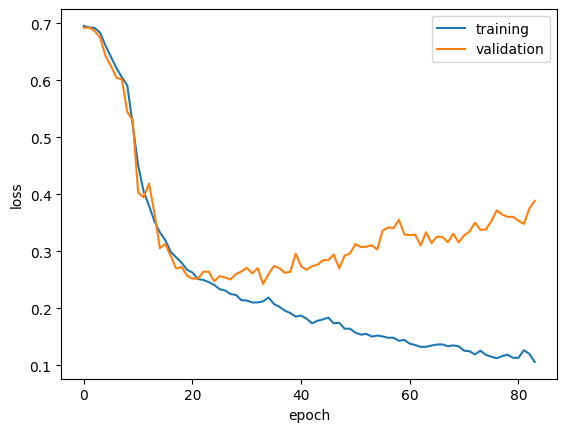

NameError: name 'fl_to_test_dataset' is not defined

In [13]:
# 18k: Search({'batch_size': 256, 'dropout': 0.18487514607572908, 'dropout1': 0.01126052479832164, 'dropout2': 0.01028606054274003, '
# epochs': 35, 'input_x': 936, 'input_y': 6, 'learning_rate': 0.001615360461069411, 'units': 96}) SCORE: 0.19302 at epoch 30
# 9k: Search({'batch_size': 128, 'dropout': 0.1762115551543323, 'dropout1': 0.08006696635006921, 'dropout2': 0.03873240626095917,
# 'epochs': 35, 'input_x': 936, 'input_y': 6, 'learning_rate': 0.006706622784221361, 'units': 128}) SCORE: 0.23825 at epoch 33
seed = 123
set_seed(seed)

batch_size = 256#128
units = 96#128 #151
dropout = 0.185# 0.176#0.187
dropout1 = 0.0112# 0.08 #0.04
dropout2 = 0.01# 0.0387 #0.02
learning_rate = 0.0016 #0.0067#3e-4
for k, v in fl_to_dataset.items():
  if k != 'r-a-d-i-s':
    continue

  train_features, val_features, normalized_train_labels, normalized_val_labels = v
  print(k)
  best_model = create_gru_model(
    input_x=train_features.shape[1],
    input_y=train_features.shape[2],
    units=units,
    dropout=dropout,
    dropout1=dropout1,
    dropout2=dropout2,
    learning_rate=learning_rate)

  prefix = 'rlf_wm'
  num_train_agents = limit
  identifier = f'{prefix}_{k}_{num_train_agents}a_B{batch_size}_U{units}_D{dropout}_D{dropout1}_D{dropout2}_{learning_rate}'
  print(identifier)


  callbacks = [EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)]

  start = time.time()
  history = best_model.fit(
        train_features,
        normalized_train_labels,
        epochs=600,
        batch_size=batch_size,
        callbacks=callbacks,
        validation_data = (val_features, normalized_val_labels),
        verbose=2)

  end = time.time()

  # Save the loss data
  best_model.save(f'{TEST_RESULT_DIR}/{identifier}_model.keras')
  plot_loss(history.history, f"{TEST_RESULT_DIR}/{identifier}_loss_plot.png", True)

  all_test_features, all_test_labels_cat = fl_to_test_dataset[k]
  prediction = best_model.predict(all_test_features)
  # If you have custom class names:
  df = pd.DataFrame(prediction, columns=LIST_OF_MODELS)
  df.to_csv(f"{TEST_RESULT_DIR}/{identifier}_pred_prob.csv", index=False)

  accr = best_model.evaluate(all_test_features, all_test_labels_cat)
  print('Test set\n  Loss: {:0.3f}\n  Accuracy: {:0.3f}'.format(accr[0], accr[1]))

rlf_wm_18000a_B256_U96_D0.185_D0.0112_D0.01_0.0016


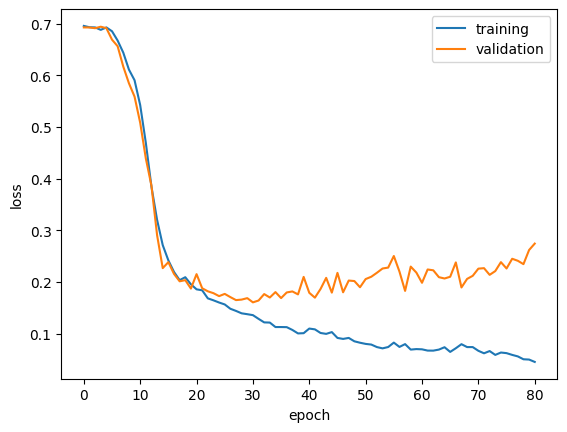

In [ ]:
TEST_RESULT_DIR = RESULT_DIR + '/RLF-WM'
identifier = f'{prefix}_{N_TRAIN_AGENT}a_B{batch_size}_U{units}_D{dropout}_D{dropout1}_D{dropout2}_{learning_rate}'
print(identifier)
# Save the loss data
best_model.save(f'{TEST_RESULT_DIR}/{identifier}_model.keras')
plot_loss(history.history, f"{TEST_RESULT_DIR}/{identifier}_loss_plot.png", True)

# Model Evaluation

In [ ]:
accr = best_model.evaluate(all_test_features, all_test_labels_cat)
print('Test set\n  Loss: {:0.3f}\n  Accuracy: {:0.3f}'.format(accr[0], accr[1]))

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - acc: 0.9360 - loss: 0.1737
Test set
  Loss: 0.174
  Accuracy: 0.936


### Confusion Matrix

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
Log Loss: 0.287



[Text(0.5, 3.722222222222216, 'Predicted model'),
 Text(20.72222222222222, 0.5, 'Simulated model'),
 Text(0.5, 1.0, 'GRU Confusion Matrix')]

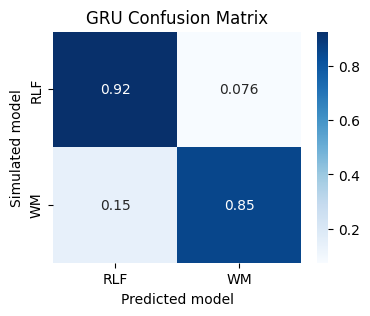

In [15]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import (
    log_loss,
)

num_test_agents = len(test_data.agentid.unique())
prediction = best_model.predict(all_test_features)
print('Log Loss: {:0.3f}\n'.format(log_loss(all_test_labels, prediction, labels=None)))

y_true, y_pred = all_test_labels, np.argmax(prediction, axis=1)
cf_matrix = confusion_matrix(y_true, y_pred)

fig = plt.figure(figsize=(4, 3))
ax = sns.heatmap(cf_matrix/num_test_agents, annot=True, cmap="Blues",
            xticklabels=LIST_OF_MODELS, yticklabels=LIST_OF_MODELS)

ax.set(xlabel='Predicted model', ylabel='Simulated model', title='GRU Confusion Matrix')

In [ ]:
# Find the indices where y_true is not equal to y_pred
mismatched_indices = np.where(y_true != y_pred)[0]
matched_indices = np.where(y_true == y_pred)[0]
print("Indices where y_true != y_pred:")
print(mismatched_indices)
grouped_data = test_data.groupby(['model_type', 'agentid']).agg({'beta': 'first', 'alpha0': 'first', 'alpha1': 'first', 'alpha': 'first'}).reset_index()

# Use iloc to select rows based on mismatched_indices
mismatched_rows = grouped_data.iloc[mismatched_indices]
matched_rows = grouped_data.iloc[matched_indices]

Indices where y_true != y_pred:
[  4  52  56  80  91  97 144 146 147 149 154 160 164 171 180 188 195 196
 201 205 222 230 233 245 249 254 265 270 273 294 298 304 306 321 330 337
 342 361 366 394 408 410 415 431 436 470 474 496 511 517 528 529 554 555
 575 602 608 613 616 623 630 635 639 667 679 683 684 689 700 708 720 756
 765 767 774 789 792 796 799 821 826 830 841 842 860 874 884 885 887 890
 929 939 953 966 988]


KeyError: "Column(s) ['alpha0', 'alpha1'] do not exist"

In [ ]:
fig, axes = plt.subplots(ncols=2, figsize=(8, 3), sharey=True)
for ax, model in zip(axes, LIST_OF_MODELS):
  sns.scatterplot(data=mismatched_rows[mismatched_rows.model_type == model], x='beta', y='alpha', color='red', alpha=0.5, label='mismatched', ax=ax)
  sns.scatterplot(data=matched_rows[matched_rows.model_type == model], x='beta', y='alpha', color='green', alpha=0.5, label='matched', ax=ax)
  ax.set_title(f'data from {model}')
  sns.despine()

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.scatterplot(data=mismatched_rows[mismatched_rows.model_type == '3PRL'], x='alpha0', y='alpha1', color='red', alpha=0.5, label='mismatched')
sns.scatterplot(data=matched_rows[matched_rows.model_type == '3PRL'], x='alpha0', y='alpha1', color='green', alpha=0.5, label='matched')
ax.set_title('data from 3PRL')
sns.despine()

In [ ]:
# @title Save the data
df = pd.DataFrame({'true_label': y_true, 'predicted_label': y_pred})
df.to_csv(f"{TEST_RESULT_DIR}/{identifier}_predict.csv")

### Classification Report

In [ ]:
df = pd.read_csv(f"{TEST_RESULT_DIR}/500t_predict.csv")
true_labels, predicted_labels = df['true_label'], df['predicted_label']

In [ ]:
from sklearn.metrics import classification_report

df = pd.DataFrame(classification_report(true_labels, predicted_labels, target_names=categories, output_dict=True))
dfT = df.drop(index=('support'), columns=['accuracy', 'macro avg', 'weighted avg']).T
dfT['model'] = dfT.index
dfT = dfT.melt(id_vars=['model'], var_name="score_type", value_name="score")
dfT

In [ ]:
import seaborn as sns

plt.figure(figsize=(6, 5))
ax = sns.barplot(data=dfT, x='model', y='score', hue='score_type', palette="dark", alpha=.6)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
#plt.savefig(f"{TEST_RESULT_DIR}/{identifier}_classification_report.png", bbox_inches='tight')

# GridSearch

In [ ]:
# For grid search
!pip install --upgrade keras-hypetune
!pip install -q -U keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 966.0/966.0 kB 63.6 MB/s eta 0:00:00
  Attempting uninstall: hyperopt
    Found existing installation: hyperopt 0.3.0
    Uninstalling hyperopt-0.3.0:
      Successfully uninstalled hyperopt-0.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 11.9 MB/s eta 0:00:00


In [ ]:
from kerashypetune import KerasBayesianSearch
from hyperopt import hp, Trials

model_func = get_gru_model
param_grid = {
  'input_x': train_features.shape[1],
  'input_y': train_features.shape[2],
  'units': hp.choice('units', [96, 128, 512]),
  'learning_rate': hp.loguniform('learning_rate', np.log(3e-4), np.log(3e-2)),
  'dropout': hp.uniform('dropout', .15, .25),
  'dropout1': hp.uniform('dropout1', .01, .1),
  'dropout2': hp.uniform('dropout2', .01, .05),
  'epochs': 35,
  'batch_size': hp.choice('batch_size', [128, 256, 512]),
}

kbs = KerasBayesianSearch(
    model_func,
    param_grid,
    monitor='val_loss',
    greater_is_better=False,
    n_iter=10,
    sampling_seed=33)

callbacks = [EarlyStopping(monitor='val_loss', patience=35)]
kbs.search(
    train_features,
    normalized_train_labels,
    trials=Trials(),
    validation_data=(val_features, normalized_val_labels),
    callbacks=callbacks)

print(kbs.best_params)
print(kbs.scores)


10 trials detected for ('input_x', 'input_y', 'units', 'learning_rate', 'dropout', 'dropout1', 'dropout2', 'epochs', 'batch_size')

***** (1/10) *****
Search({'batch_size': 256, 'dropout': 0.21842392063245403, 'dropout1': 0.04371536261349302, 'dropout2': 0.011162571672588868, 'epochs': 35, 'input_x': 936, 'input_y': 6, 'learning_rate': 0.0020983717713673558, 'units': 512})


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/masking.py:48: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.


SCORE: 0.16329 at epoch 18

***** (2/10) *****
Search({'batch_size': 256, 'dropout': 0.1670834434291943, 'dropout1': 0.06099680952405236, 'dropout2': 0.034499058943751305, 'epochs': 35, 'input_x': 936, 'input_y': 6, 'learning_rate': 0.0005181811905295516, 'units': 96})
SCORE: 0.59253 at epoch 35

***** (3/10) *****
Search({'batch_size': 256, 'dropout': 0.15045217698983135, 'dropout1': 0.076532283427947, 'dropout2': 0.043834198149242415, 'epochs': 35, 'input_x': 936, 'input_y': 6, 'learning_rate': 0.0011870697202941616, 'units': 128})
SCORE: 0.21018 at epoch 34

***** (4/10) *****
Search({'batch_size': 512, 'dropout': 0.154764975202242, 'dropout1': 0.03977966819726573, 'dropout2': 0.020813930721435364, 'epochs': 35, 'input_x': 936, 'input_y': 6, 'learning_rate': 0.02595053868248087, 'units': 512})
SCORE: nan at epoch 1

***** (5/10) *****
Search({'batch_size': 128, 'dropout': 0.23301839255894233, 'dropout1': 0.058425055413367, 'dropout2': 0.012846644699199512, 'epochs': 35, 'input_x': 9

KeyboardInterrupt: 

In [ ]:
from kerashypetune import KerasGridSearch

# Set up hyperparameters to test
param_grid = {
    'input_x': [train_features.shape[1]],
    'input_y': [train_features.shape[2]],
    'units': 96, #[96, 128],
    'dropout': [0.2, 0.1],
    'dropout1': [0.1, 0.05],
    'dropout2': [0.01, 0.05],
    'learning_rate': 3e-4,
    'epochs': 35,
    'batch_size': 128,
}


kgs = KerasGridSearch(model_func, param_grid, monitor='val_loss', greater_is_better=False)
callbacks = [EarlyStopping(monitor='val_loss', patience=35)]
kgs.search(
    train_features,
    normalized_train_labels,
    validation_data=(val_features, normalized_val_labels), callbacks=callbacks)
print(kgs.best_params)
print(kgs.scores)


8 trials detected for ('input_x', 'input_y', 'units', 'dropout', 'dropout1', 'dropout2', 'learning_rate', 'epochs', 'batch_size')

***** (1/8) *****
Search({'input_x': 936, 'input_y': 5, 'units': 96, 'dropout': 0.2, 'dropout1': 0.1, 'dropout2': 0.05, 'learning_rate': 0.0003, 'epochs': 35, 'batch_size': 128})
SCORE: 0.69177 at epoch 33

***** (2/8) *****
Search({'input_x': 936, 'input_y': 5, 'units': 96, 'dropout': 0.2, 'dropout1': 0.1, 'dropout2': 0.01, 'learning_rate': 0.0003, 'epochs': 35, 'batch_size': 128})
SCORE: 0.69211 at epoch 23

***** (3/8) *****
Search({'input_x': 936, 'input_y': 5, 'units': 96, 'dropout': 0.2, 'dropout1': 0.05, 'dropout2': 0.05, 'learning_rate': 0.0003, 'epochs': 35, 'batch_size': 128})
SCORE: 0.69136 at epoch 31

***** (4/8) *****
Search({'input_x': 936, 'input_y': 5, 'units': 96, 'dropout': 0.2, 'dropout1': 0.05, 'dropout2': 0.01, 'learning_rate': 0.0003, 'epochs': 35, 'batch_size': 128})
SCORE: 0.69235 at epoch 12

***** (5/8) *****
Search({'input_x': 9